# 기능 A 꼭 넣을 문구: 샘플링 후보 4개 → 8개 (세 게임, 11/03)

21 "상세페이지"의 ② 게임 소개(0x72)는 생성 6번 뒤에도 꼭 넣을 문구 "스팀 찜하기"가 문장 앞이나 뒤에 따로 붙어 검사를 통과하지 못했다(`dp_copy_records.csv`). 같은 지시문·같은 이미지(x72_scene_0497, seed 0)인 13 ③의 결과도 같은 문장이다. 13 ③에서 0x72 실패 3건은 모두 이 유형(문구를 문장 앞뒤에 붙임)이었다(`nx_must_scored.csv`의 fail_attached).

지금 방식(13 ③, 21에서 쓰는 방식)은 첫 생성이 검사에 걸리면 같은 입력으로 샘플링 후보 4개를 만들어 실패 항목이 가장 적은 것을 고르고, 그래도 걸리면 구체적 재요청을 1번 한다. 이 노트북은 샘플링 후보만 4개에서 8개로 늘려, 통과율이 오르는지와 시간이 얼마나 늘어나는지를 세 게임에서 확인한다.

| 후보 | 지시문 | 샘플링 후보 | 구체적 재요청 | 최대 생성 횟수 |
|---|---|---|---|---|
| 기준 ③ `n4+example+fb_specific` | 13 ① 지시문 예시 | 4개 | 1번 | 6번 |
| 후보 `n8+example+fb_specific` | 같음 | 8개 | 1번 | 10번 |

- 입력: 13·10과 같은 표본(게임마다 5장), seed 0·1·2. 꼭 넣을 문구는 냥기사 "11월 업데이트 기념 30% 할인", 0x72 "스팀 찜하기", KayKit "신규 영웅 로그 추가".
- 기준 ③은 다시 돌리지 않고 기록을 읽는다: 냥기사·0x72는 13 `nx_must_compare.csv`, KayKit은 10 `kk_must_compare.csv`. 두 기록의 지시문·재요청 문구·검사 규칙은 이 노트북과 같다(19에서 고친 조사는 ③의 재요청 문장에 들어가지 않았고, "스팀 찜하기"·"신규 영웅 로그 추가"는 받침이 없어 고치기 전과 후가 같다).
- 설정 셀·검사 규칙·재요청 문구는 19와 같다. 바뀐 것은 대상 게임(세 게임), 샘플링 후보 수(8개), 기록 파일 이름이다.
- 기록 (`outputs/local_vlm/`, 13·10 파일은 읽기만 함)
  - `n8_must_config.json`, `n8_must_compare.csv`, `n8_must_runs.csv`
  - `n8_must_scored.csv`, `n8_must_summary.csv`, `n8_must_by_game.csv`, `n8_must_fail_types.csv`, `n8_must_compare.png`, `n8_must_examples.csv`
- 진행 출력: 생성은 별도 프로세스에서 하고, 모델 로드 시작·끝과 건마다 `[시각 | 경과 | VRAM] i/전체`를 바로 출력한다.
- 예상 시간: 기준 ③ 실행 1번이 냥기사·0x72 10건 255.9~266.5초(`nx_must_runs.csv`), KayKit 5건 180.9~197.4초(`kk_must_runs.csv`)였다. 후보 8개는 후보 생성 단계가 길어져 seed 하나(15건, 모델 로드 1번)에 약 8~10분, 세 seed 약 25~30분으로 추정한다. 실제 시간은 `n8_must_runs.csv`에 남는다.
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 설정 (09와 같음)

In [1]:
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs' / 'local_vlm'
OUT_DIR.mkdir(parents=True, exist_ok=True)

QWEN_REPO = 'Qwen/Qwen3-VL-8B-Instruct'
MAX_NEW_TOKENS = 512

# 기능 A 입력: 02와 같은 표본(게임마다 5장, seed 0)과 같은 지시문
GAMES = {
    'nai': dict(files=sorted((RAW / 'nai/lora_gen').glob('*_screenshot.png')),
                info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임'),
    'x72': dict(files=sorted((RAW / 'pixel_0x72/scenes').glob('x72_scene_*.png')), info='픽셀 아트 던전 탐험 게임'),
    'kaykit': dict(files=sorted((RAW / 'kaykit/renders').glob('kk_*.png')), info='로우폴리 3D 판타지 어드벤처 게임'),
}
rng = random.Random(0)
SAMPLES = [(g, p) for g, d in GAMES.items() for p in rng.sample(d['files'], 5)]
TONE = '밝고 친근한 톤'
SYSTEM_A = '너는 1인 인디게임 개발사의 마케팅 카피라이터다.'

# 08 "규칙 적용 지시문"과 같은 판매 포인트·사용자 입력·금지 표현·지시문
# 게임 기본 판매 포인트 (각 게임 데이터 파일에 있는 요소만 사용)
GAME_POINTS = {
    'nai': ['빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션', '개 기사·부엉이 마법사·토끼 상인 동료',
            '떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지', '동화책 같은 손그림 색감'],
    'x72': ['위에서 내려다보는 16비트 픽셀 던전', '기사·엘프·마법사·드워프 중 골라 플레이',
            '오크·해골·좀비·네크로맨서 등 몬스터', '금화·물약·보물상자(미믹 포함) 수집'],
    'kaykit': ['바바리안·기사·마법사·로그 등 5명의 로우폴리 영웅', '한손·양손 무기, 석궁, 지팡이를 쓰는 전투',
               '회피·막기·연속 공격 액션'],
}
# 사용자 입력 예시 (게임마다 1개). 냥기사는 판촉 표현이 사용자 입력에 있을 때 허용되는지 보려고 할인 문구를 넣음
USER_POINTS = {
    'nai': dict(points='11월 업데이트로 신규 동료 추가', must='11월 업데이트 기념 30% 할인'),
    'x72': dict(points='4인 로컬 협동 플레이 지원', must='스팀 찜하기'),
    'kaykit': dict(points='영웅마다 다른 전용 스킬', must='신규 영웅 로그 추가'),
}
BANNED_PROMO = ['할인', '특가', '무료', '이벤트', '출시', '사전예약', '선물']
BANNED_CLICHE = ['모험을 떠나', '떠나보세요', '떠나볼까요', '함께 떠나', '기다리고 있어요', '귀여운 친구들']

INSTRUCTION_A2 = '''게임 정보: {info}
{user_block}
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
{points}
요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: {cliche}
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''


# 08 "꼭 넣을 문구 처리 방식 비교"와 같은 검증 규칙·지시문 보강·입력
MUST_CSV = OUT_DIR / 'must_phrase_compare.csv'
# Instructor 문서 reask 예시값
MAX_RETRY = 2

VALIDATOR = r"""
import json, re


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def _josa(word, with_final, without_final):
    # 마지막 글자에 받침이 있으면 with_final(이·을), 없으면 without_final(가·를). 한글이 아니면 without_final
    ch = word.strip()[-1:] or ' '
    if '가' <= ch <= '힣' and (ord(ch) - 0xAC00) % 28:
        return with_final
    return without_final


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음 (02와 같은 기준)
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def integrated(sns, must):
    if must not in sns or n_sentences(sns) != 1:
        return False
    if len(re.findall(r'[가-힣]', sns.replace(must, ' '))) < 8:
        return False
    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
    return True


def check(text, must, allowed, banned_promo, banned_cliche, need_must):
    d = parse_json(text)
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return ['JSON 형식이 아니다. {"store": ["문장1", "문장2"], "sns": "문장"} 형식으로만 써야 한다.']
    store = [str(x) for x in d['store']]
    sns = d['sns']
    probs = []
    n_store, n_sns = sum(n_sentences(x) for x in store), n_sentences(sns)
    if n_store != 2:
        probs.append(f'store는 정확히 2문장이어야 하는데 {n_store}문장이다.')
    if n_sns != 1:
        probs.append(f'sns는 정확히 1문장이어야 하는데 {n_sns}문장이다.')
    if need_must:
        if must not in sns:
            probs.append(f'꼭 넣을 문구 "{must}"{_josa(must, "이", "가")} sns 문장에 글자 그대로 들어 있지 않다.')
        elif not integrated(sns, must):
            probs.append(f'꼭 넣을 문구 "{must}"{_josa(must, "이", "가")} 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.')
    body = ' '.join(store) + ' ' + sns
    words = [w for w in banned_promo if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    if words or nums:
        probs.append(f'사용자 입력에 없는 판촉 표현을 썼다: {", ".join(words + nums)}')
    cl = [c for c in banned_cliche if c in body]
    if cl:
        probs.append(f'쓰지 말라는 표현을 썼다: {", ".join(cl)}')
    return probs
"""
exec(VALIDATOR)

RULE1 = '1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.'
assert INSTRUCTION_A2.count(RULE1) == 1
INSTRUCTION_A3 = INSTRUCTION_A2.replace(RULE1, '\n'.join([
    RULE1,
    '   "꼭 넣을 문구"는 sns 문장 안에 문장의 일부로 넣고, 문장 앞이나 뒤에 따로 붙이지 마.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "데모 플레이 가능"): "눈 덮인 마을의 여우 기사 이야기, 데모 플레이 가능 소식을 지금 확인해 보세요."',
    '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"']))


def must_task(g, p, method):
    u = USER_POINTS[g]
    if method == 'pin':
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']}", INSTRUCTION_A2
    else:
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\"", INSTRUCTION_A3
    prompt = instr.format(info=GAMES[g]['info'], user_block=ub, points='\n'.join('- ' + x for x in GAME_POINTS[g]),
                          tone=TONE, cliche=', '.join(BANNED_CLICHE))
    return dict(method=method, item=p.name, game=g, image=str(p.resolve()), system=SYSTEM_A, prompt=prompt,
                must=u['must'], allowed=' '.join(u.values()), need_must=(method == 'retry'))


MUST_TASKS = [must_task(g, p, m) for m in ['retry', 'pin'] for g, p in SAMPLES]


# 08 "비교 지표와 그래프"와 같은 채점 함수
def score_must(text, g, method):
    d = parse_json(text)
    u = USER_POINTS[g]
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return dict(json_ok=False, format_ok=False, must_kept=method == 'pin', integrated=False, promo_violation=np.nan, cliche=np.nan)
    store, sns = [str(x) for x in d['store']], d['sns']
    body = ' '.join(store) + ' ' + sns
    allowed = ' '.join(u.values())
    words = [w for w in BANNED_PROMO if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    return dict(json_ok=True,
                format_ok=sum(n_sentences(x) for x in store) == 2 and n_sentences(sns) == 1,
                must_kept=True if method == 'pin' else u['must'] in sns,
                integrated=False if method == 'pin' else integrated(sns, u['must']),
                promo_violation=bool(words or nums), cliche=any(c in body for c in BANNED_CLICHE))

print(len(MUST_TASKS), 'tasks |', sum(t['method'] == 'retry' for t in MUST_TASKS), 'retry tasks')

30 tasks | 15 retry tasks


## 후보 지시문·재요청 문구

In [2]:
KK_CSV = OUT_DIR / 'n8_must_compare.csv'
KK_RUNS_CSV = OUT_DIR / 'n8_must_runs.csv'
KK_CONFIG = OUT_DIR / 'n8_must_config.json'
# 기준 ③ 기록: 냥기사·0x72는 13, KayKit은 10
BASE_CSVS = {'nai': OUT_DIR / 'nx_must_compare.csv', 'x72': OUT_DIR / 'nx_must_compare.csv',
             'kaykit': OUT_DIR / 'kk_must_compare.csv'}
BASE_LABEL = 'n4+example+fb_specific'
KK_SEEDS = [0, 1, 2]
TEST_GAMES = ['nai', 'x72', 'kaykit']
# 기준 ③은 4개
N_CAND = 8

# ① 지시문 예시 추가: 09 지시문(INSTRUCTION_A3)의 나쁜 예 줄 다음에 명사로 끝나는 문구의 예를 더함
BAD_LINE = '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"'
assert INSTRUCTION_A3.count(BAD_LINE) == 1
INSTRUCTION_EX = INSTRUCTION_A3.replace(BAD_LINE, '\n'.join([
    BAD_LINE,
    '   꼭 넣을 문구가 명사로 끝나면 단어를 바꾸지 말고 뒤에 조사를 붙여 넣어줘.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "신규 맵 사막 추가"): "모래바람이 부는 협곡을 달리는 기사단, 신규 맵 사막 추가로 더 넓어진 세계를 만나 보세요."',
    '   나쁜 예: "신규 맵으로 사막이 추가되어 모래바람 협곡을 달릴 수 있어요." (문구를 바꿔 씀)']))

# ② 구체적 재요청: 09 (가) 재요청 문구 + 실패 이유별 고치는 방법
FB_HEAD = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'
FB_HINTS = {
    'missing': '- 고치는 방법: "{must}"의 단어를 바꾸거나 나누거나 순서를 바꾸지 말고 글자 그대로 sns 문장에 넣어. 바로 뒤에 조사를 붙여도 된다 (예: "{must_ro}", "{must} 소식과 함께").',
    'attached': '- 고치는 방법: "{must}"{eul} 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, {must_ro} 더 다채로워진 전투를 만나 보세요.").',
}
# 실패 이유 문장(VALIDATOR check)에서 어떤 고치는 방법을 붙일지 고르는 표시
FB_KEYS = {'missing': '글자 그대로 들어 있지 않다', 'attached': '따로 붙어 있다'}

KK_TASKS_BASE = [t for t in MUST_TASKS if t['method'] == 'retry' and t['game'] in TEST_GAMES]


def with_ro(must):
    # 10은 "{문구}로" 고정 → 받침(ㄹ 제외) 뒤에는 "으로"
    c = must[-1]
    if '가' <= c <= '힣' and (ord(c) - 0xAC00) % 28 not in (0, 8):
        return must + '으로'
    return must + '로'


assert with_ro('신규 영웅 로그 추가') == '신규 영웅 로그 추가로'  # 10과 같음
assert with_ro('11월 업데이트 기념 30% 할인') == '11월 업데이트 기념 30% 할인으로'
assert with_ro('스팀 찜하기') == '스팀 찜하기로'


def with_prompt(t, instr):
    u = USER_POINTS[t['game']]
    ub = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\""
    prompt = instr.format(info=GAMES[t['game']]['info'], user_block=ub,
                          points='\n'.join('- ' + x for x in GAME_POINTS[t['game']]), tone=TONE,
                          cliche=', '.join(BANNED_CLICHE))
    return dict(t, prompt=prompt)


# 지시문을 바꾸지 않은 경우 09와 같은 프롬프트인지 확인
assert all(with_prompt(t, INSTRUCTION_A3)['prompt'] == t['prompt'] for t in KK_TASKS_BASE)

# (이름, 지시문, 구체적 재요청 여부)
# ③과 같은 지시문·재요청, 샘플링 후보만 8개
KK_RUNS = [('n8+example+fb_specific', INSTRUCTION_EX, True)]
KK_TASKS = {label: [with_prompt(t, instr) for t in KK_TASKS_BASE] for label, instr, _ in KK_RUNS}
for g in TEST_GAMES:
    print(g, sum(t['game'] == g for t in KK_TASKS_BASE), '건:', [t['item'] for t in KK_TASKS_BASE if t['game'] == g],
          '| 꼭 넣을 문구:', USER_POINTS[g]['must'])
print('\n[① 지시문에서 더한 부분]')
print(INSTRUCTION_EX.split(BAD_LINE)[1].split('2. ')[0])
for g in TEST_GAMES:
    _m = USER_POINTS[g]['must']
    print(f'[② 재요청 예시 ({g}): 문구가 앞뒤에 붙은 경우]')
    print(FB_HEAD + f'- 꼭 넣을 문구 "{_m}"{_josa(_m, "이", "가")} 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.\n'
          + FB_HINTS['attached'].format(must=_m, must_ro=with_ro(_m), eul=_josa(_m, '을', '를')) + '\n')


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


import importlib.metadata
import platform

# 보고서용 실험 설정 기록
config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), model=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, seeds=KK_SEEDS, n_cand=N_CAND,
    baseline=f'{BASE_LABEL}: 냥기사·0x72 = 13 (nx_must_compare.csv), KayKit = 10 (kk_must_compare.csv)', test_games=TEST_GAMES,
    josa_rule='재요청 예시의 조사: 받침(ㄹ 제외) 있으면 으로, 없으면 로 (10은 로 고정). 10/30: 실패 이유·재요청 문장의 이/가·을/를도 받침에 맞춤',
    runs=[dict(label=label, instruction='example' if instr is INSTRUCTION_EX else '09 INSTRUCTION_A3', fb_specific=fb,
               max_generations=1 + N_CAND + (1 if fb else 0)) for label, instr, fb in KK_RUNS],
    tasks=[dict(item=t['item'], game=t['game'], must=t['must'], allowed=t['allowed']) for t in KK_TASKS_BASE],
    system_prompt=SYSTEM_A, prompt_base=KK_TASKS_BASE[0]['prompt'], prompt_example=with_prompt(KK_TASKS_BASE[0], INSTRUCTION_EX)['prompt'],
    fb_head=FB_HEAD, fb_hints=FB_HINTS, fb_keys=FB_KEYS, banned_promo=BANNED_PROMO, banned_cliche=BANNED_CLICHE,
    validator_strict=VALIDATOR,
    versions={p: pkg_version(p) for p in ['torch', 'transformers', 'accelerate', 'pillow', 'pandas', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
KK_CONFIG.write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding='utf-8')
print('\n설정 기록:', KK_CONFIG.name, '| GPU:', config['gpu'], '| transformers', config['versions']['transformers'])

nai 5 건: ['gen_0729_screenshot.png', 'gen_0733_screenshot.png', 'gen_0685_screenshot.png', 'gen_0713_screenshot.png', 'gen_0745_screenshot.png'] | 꼭 넣을 문구: 11월 업데이트 기념 30% 할인
x72 5 건: ['x72_scene_0497.png', 'x72_scene_0414.png', 'x72_scene_0310.png', 'x72_scene_0488.png', 'x72_scene_0366.png'] | 꼭 넣을 문구: 스팀 찜하기
kaykit 5 건: ['kk_0223.png', 'kk_0516.png', 'kk_0142.png', 'kk_0288.png', 'kk_0143.png'] | 꼭 넣을 문구: 신규 영웅 로그 추가

[① 지시문에서 더한 부분]

   꼭 넣을 문구가 명사로 끝나면 단어를 바꾸지 말고 뒤에 조사를 붙여 넣어줘.
   좋은 예 (다른 게임, 꼭 넣을 문구 "신규 맵 사막 추가"): "모래바람이 부는 협곡을 달리는 기사단, 신규 맵 사막 추가로 더 넓어진 세계를 만나 보세요."
   나쁜 예: "신규 맵으로 사막이 추가되어 모래바람 협곡을 달릴 수 있어요." (문구를 바꿔 씀)

[② 재요청 예시 (nai): 문구가 앞뒤에 붙은 경우]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 꼭 넣을 문구 "11월 업데이트 기념 30% 할인"이 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.
- 고치는 방법: "11월 업데이트 기념 30% 할인"을 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, 11월 업데이트 기념 30% 할인으로 더 다채로워진 전투를 만나 보세요.").

[② 재요청 예시 (x72): 문구가 앞뒤에 붙은 경우]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.


## 생성 (후보 8개 × seed 3개 × 세 게임 15건)

In [3]:
CHILD_KK = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
FIELDS = ['method', 'seed', 'item', 'game', 'n_gen', 'sec_total', 'peak_vram_gb', 'load_sec', 'text', 'texts_all',
          'problems', 'fb_sent', 'identical_repeats', 'gen_cfg', 'error']


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()


def stamp():
    # 멈춤 여부를 바로 알 수 있게 시각·경과·VRAM(현재/최대)
    m, sec = divmod(int(time.perf_counter() - t0), 60)
    return (f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{sec:02d} | VRAM '
            f'{torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)]')


print(stamp(), 'Qwen 로드 시작', a['label'], 'seed', a['seed'], flush=True)
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 1)
gc = model.generation_config
GEN_CFG = json.dumps(dict(temperature=gc.temperature, top_p=gc.top_p, top_k=gc.top_k,
                          repetition_penalty=getattr(gc, 'repetition_penalty', None)))
print(stamp(), 'Qwen 로드 끝', load_sec, 's | sampling defaults', GEN_CFG, flush=True)


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def probs_of(text, t):
    return check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], True)


def with_ro(must):
    c = must[-1]
    if '가' <= c <= '힣' and (ord(c) - 0xAC00) % 28 not in (0, 8):
        return must + '으로'
    return must + '로'


def feedback(probs, must):
    # 실패 이유 줄 아래에, 해당하는 고치는 방법 줄을 붙임
    out = []
    for p in probs:
        out.append('- ' + p)
        for key, mark in a['fb_keys'].items():
            if mark in p:
                out.append(a['fb_hints'][key].format(must=must, must_ro=with_ro(must), eul=_josa(must, '을', '를')))
    return a['fb_head'] + '\n'.join(out)


for k, t in enumerate(a['tasks'], 1):
    rec = dict(method=a['label'], seed=a['seed'], item=t['item'], game=t['game'], load_sec=load_sec, gen_cfg=GEN_CFG)
    try:
        torch.manual_seed(a['seed'])
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                                 {'type': 'text', 'text': t['prompt']}]}]
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts = gen(messages, sample=False)
        final, probs = texts[0], probs_of(texts[0], t)
        fb_sent = ''
        if probs:
            # (나): 같은 입력으로 샘플링 후보 n개 → 실패 항목이 가장 적은 후보
            cands = gen(messages, sample=True, n=a['n_cand'])
            texts += cands
            n_bad, _, best = min((len(probs_of(c, t)), i, c) for i, c in enumerate(cands))
            if n_bad < len(probs):
                final, probs = best, probs_of(best, t)
            if probs and a['fb_specific']:
                # ② 구체적 재요청: 가장 나은 글 + 실패 이유 + 고치는 방법
                fb_sent = feedback(probs, t['must'])
                m2 = messages + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                                 {'role': 'user', 'content': [{'type': 'text', 'text': fb_sent}]}]
                fix = gen(m2, sample=True)[0]
                texts.append(fix)
                fp = probs_of(fix, t)
                if len(fp) < len(probs):
                    final, probs = fix, fp
        rec.update(n_gen=len(texts), sec_total=round(time.perf_counter() - t1, 2),
                   peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2), text=final,
                   texts_all=json.dumps(texts, ensure_ascii=False), problems=json.dumps(probs, ensure_ascii=False),
                   fb_sent=fb_sent, identical_repeats=sum(texts[i] == texts[i - 1] for i in range(1, len(texts))))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(stamp(), f"{k}/{len(a['tasks'])}", a['label'], a['seed'], t['item'], '생성', rec.get('n_gen'), '번',
          rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
"""

done = set()
if KK_CSV.exists():
    _r = pd.read_csv(KK_CSV, keep_default_na=False, dtype=str)
    _r = _r[_r.error == '']
    done = set(zip(_r.method, _r.seed.astype(int), _r['item']))
for label, instr, fb in KK_RUNS:
    for seed in KK_SEEDS:
        todo = [t for t in KK_TASKS[label] if (label, seed, t['item']) not in done]
        if not todo:
            print(label, seed, '이미 완료 → 건너뜀')
            continue
        t_run = time.perf_counter()
        arg = json.dumps(dict(repo=QWEN_REPO, label=label, seed=seed, n_cand=N_CAND, fb_specific=fb,
                              max_new_tokens=MAX_NEW_TOKENS, validator=VALIDATOR, banned_promo=BANNED_PROMO,
                              banned_cliche=BANNED_CLICHE, fb_head=FB_HEAD, fb_hints=FB_HINTS, fb_keys=FB_KEYS,
                              out=str(KK_CSV.resolve()), tasks=todo))
        # 진행 상황을 셀 출력에 바로 보여 줌 (오류 메시지도 같은 출력으로)
        p = subprocess.Popen([sys.executable, '-c', CHILD_KK], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                             stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                             env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
        p.stdin.write(arg)
        p.stdin.close()
        tail = []
        for line in p.stdout:
            print(line, end='', flush=True)
            tail = (tail + [line])[-20:]
        p.wait()
        sec = round(time.perf_counter() - t_run, 1)
        # 보고서용 실행 기록: 후보×seed마다 시각·시간·VRAM·건수·오류
        _w = pd.read_csv(KK_CSV, keep_default_na=False, dtype=str) if KK_CSV.exists() else pd.DataFrame()
        _w = _w[(_w.method == label) & (_w.seed == str(seed))] if len(_w) else _w
        run_rec = dict(label=label, fb_specific=fb, instruction='example' if instr is INSTRUCTION_EX else 'A3', seed=seed,
                       started=time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(time.time() - sec)),
                       ended=time.strftime('%Y-%m-%d %H:%M:%S'), sec_total=sec, returncode=p.returncode,
                       n_tasks=len(todo), n_rows=len(_w), n_errors=int((_w.error != '').sum()) if len(_w) else 0,
                       load_sec=float(_w.load_sec.iloc[0]) if len(_w) and _w.load_sec.iloc[0] else None,
                       peak_vram_gb=pd.to_numeric(_w.peak_vram_gb, errors='coerce').max() if len(_w) else None,
                       stderr_tail=''.join(tail)[-300:] if p.returncode != 0 else '')
        pd.DataFrame([run_rec]).to_csv(KK_RUNS_CSV, mode='a', header=not KK_RUNS_CSV.exists(), index=False,
                                       encoding='utf-8-sig')
        print(f'{label} seed {seed}: {sec}초 (모델 로드 포함), 오류 {run_rec["n_errors"]}건', flush=True)

W1103 08:38:38.685000 31988 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1103 08:38:38.767000 31988 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
[08:38:39 | 경과 0:00:00 | VRAM 0.0GB (최대 0.0GB)] Qwen 로드 시작 n8+example+fb_specific seed 0

Loading weights: 100%|██████████| 750/750 [00:10<00:00, 73.10it/s] 
[08:38:53 | 경과 0:00:14 | VRAM 16.3GB (최대 16.3GB)] Qwen 로드 끝 14.2 s | sampling defaults {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}
[08:39:04 | 경과 0:00:25 | VRAM 16.3GB (최대 16.9GB)] 1/15 n8+example+fb_specific 0 gen_0729_scree

## 지표와 그래프

기준 ③ 건수: {'kaykit': 15, 'nai': 15, 'x72': 15} | 이번 건수: {'kaykit': 15, 'nai': 15, 'x72': 15}
후보별 건수: {'n4+example+fb_specific': 45, 'n8+example+fb_specific': 45}


format_ok      must_kept      integrated        cliche  \
                            mean  std      mean  std       mean    std   mean   
method                                                                          
n4+example+fb_specific       1.0  0.0       1.0  0.0      0.933  0.000  0.044   
n8+example+fb_specific       1.0  0.0       1.0  0.0      0.844  0.077  0.000   

                              all_rules         n_gen            sec         \
                          std      mean    std   mean    std    mean    std   
method                                                                        
n4+example+fb_specific  0.038     0.889  0.038  3.822  0.038  23.706  0.474   
n8+example+fb_specific  0.000     0.844  0.077  6.533  0.133  20.508  0.937   

                       fb_used         
                          mean    std  
method                                 
n4+example+fb_specific   0.156  0.038  
n8+example+fb_specific   0.200  0.133

게임별 규칙 전부 통과 (seed 3개 평균)


game,kaykit,nai,x72
method,,,
n4+example+fb_specific,1.0,0.867,0.800
n8+example+fb_specific,1.0,1.000,0.533


실패 유형별 건수 (seed 3개 합)


,fail_format,fail_missing,fail_attached,fail_promo,fail_cliche,n_failed,n
method,,,,,,,
n4+example+fb_specific,0,0,3,0,2,5,45
n8+example+fb_specific,0,0,7,0,0,7,45


실행 기록 (n8_must_runs.csv)


,label,fb_specific,instruction,seed,started,ended,sec_total,returncode,n_tasks,n_rows,n_errors,load_sec,peak_vram_gb,stderr_tail
0,n8+example+fb_specific,True,example,0,2026-11-03 08:38:21,2026-11-03 08:44:15,354.1,0,15,15,0,14.2,20.15,
1,n8+example+fb_specific,True,example,1,2026-11-03 08:44:15,2026-11-03 08:49:57,341.6,0,15,15,0,14.2,20.15,
2,n8+example+fb_specific,True,example,2,2026-11-03 08:49:57,2026-11-03 08:55:24,326.7,0,15,15,0,14.7,20.15,


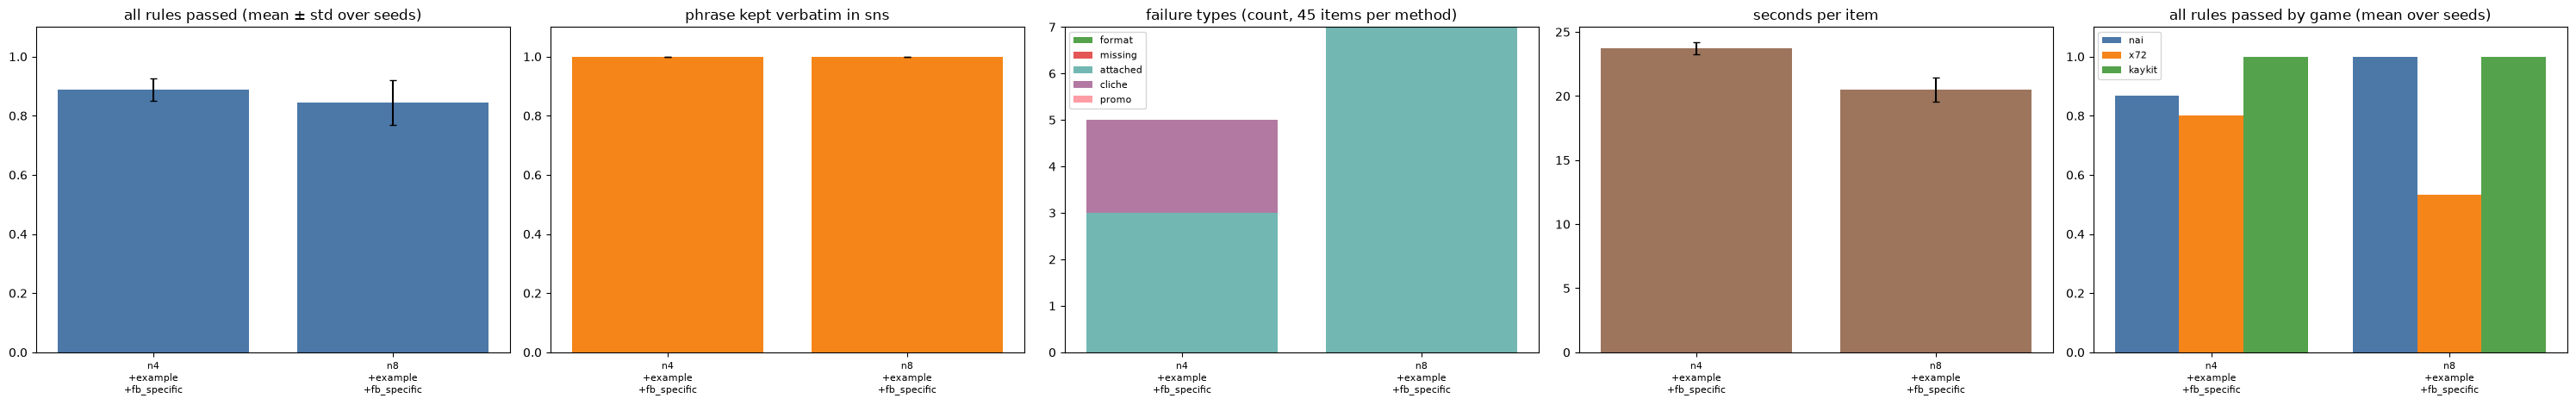

첫 생성에서 검사에 걸린 건 (후보 단계로 간 건)


n  all_rules  n_gen     sec
method                 game                                
n4+example+fb_specific kaykit   9      1.000  5.111  33.332
                       nai      9      0.778  5.333  28.150
                       x72     12      0.750  5.250  26.088
n8+example+fb_specific kaykit   9      1.000  9.111  23.560
                       nai      9      1.000  9.111  24.222
                       x72     12      0.417  9.583  28.110

x72_scene_0497 seed 0:


,method,n_gen,sec,all_rules,text
15,n4+example+fb_specific,6,31.90,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."
50,n8+example+fb_specific,10,31.57,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."


In [4]:
# 기준 ③: 13(냥기사·0x72) + 10(KayKit) 기록
base = []
for g in TEST_GAMES:
    _b = pd.read_csv(BASE_CSVS[g], keep_default_na=False)
    base.append(_b[(_b.game == g) & (_b.error == '') & (_b.method == BASE_LABEL)])
base = pd.concat(base, ignore_index=True)
new =pd.read_csv(KK_CSV, keep_default_na=False)
new = new[new.error == '']
# 기준과 이번 실행의 이미지·seed가 같은지 확인
_key = lambda d: set(zip(d.game, d['item'], d.seed.astype(int)))
assert _key(base.drop_duplicates(['seed', 'item'])) == {(t['game'], t['item'], s) for t in KK_TASKS_BASE for s in KK_SEEDS}, '기준 기록의 표본이 다름'
print('기준 ③ 건수:', base.drop_duplicates(['seed', 'item']).groupby('game').size().to_dict(),
      '| 이번 건수:', new.drop_duplicates(['method', 'seed', 'item']).groupby('game').size().to_dict())
kk = pd.concat([base.drop_duplicates(['method', 'seed', 'item'], keep='last'),
                new.drop_duplicates(['method', 'seed', 'item'], keep='last')], ignore_index=True)
# 기준(09) 기록에는 재요청 열이 없음
kk['fb_sent'] = kk['fb_sent'].fillna('') if 'fb_sent' in kk else ''
rows = []
for _, r in kk.iterrows():
    s = score_must(r.text, r.game, 'retry')
    rows.append(dict(method=r.method, seed=int(r.seed), item=r['item'], game=r.game, n_gen=int(r.n_gen), sec=float(r.sec_total),
                     fb_used=bool(r.get('fb_sent', '')), text=r.text, **s))
kks = pd.DataFrame(rows)
kks['all_rules'] = kks.format_ok & kks.must_kept & kks.integrated & (kks.promo_violation == False) & (kks.cliche == False)
# 실패 유형 (한 건이 여러 유형에 걸릴 수 있음). 문장 안 넣기는 문구가 들어 있는 경우만 센다
kks['fail_format'] = ~kks.format_ok
kks['fail_missing'] = ~kks.must_kept
kks['fail_attached'] = kks.must_kept & ~kks.integrated
kks['fail_promo'] = kks.promo_violation == True
kks['fail_cliche'] = kks.cliche == True
KK_METHODS = [BASE_LABEL] + [label for label, _, _ in KK_RUNS]
methods = [m for m in KK_METHODS if m in set(kks.method)]

per_seed = kks.groupby(['method', 'seed']).agg(
    format_ok=('format_ok', 'mean'), must_kept=('must_kept', 'mean'), integrated=('integrated', 'mean'),
    cliche=('cliche', 'mean'), all_rules=('all_rules', 'mean'), n_gen=('n_gen', 'mean'), sec=('sec', 'mean'),
    fb_used=('fb_used', 'mean'))
summ = per_seed.groupby('method').agg(['mean', 'std']).reindex(methods)
fails = kks.groupby('method')[['fail_format', 'fail_missing', 'fail_attached', 'fail_promo', 'fail_cliche']].sum()
fails['n_failed'] = (~kks.all_rules).groupby(kks.method).sum()
fails['n'] = kks.groupby('method').size()
fails = fails.reindex(methods)
kks.to_csv(OUT_DIR / 'n8_must_scored.csv', index=False, encoding='utf-8-sig')
summ.to_csv(OUT_DIR / 'n8_must_summary.csv', encoding='utf-8-sig')
fails.to_csv(OUT_DIR / 'n8_must_fail_types.csv', encoding='utf-8-sig')
print('후보별 건수:', kks.groupby('method').size().to_dict())
display(summ.round(3))
by_game = kks.groupby(['method', 'game']).all_rules.mean().unstack().reindex(methods).round(3)
by_game.to_csv(OUT_DIR / 'n8_must_by_game.csv', encoding='utf-8-sig')
print('게임별 규칙 전부 통과 (seed 3개 평균)')
display(by_game)
print('실패 유형별 건수 (seed 3개 합)')
display(fails)
if KK_RUNS_CSV.exists():
    print('실행 기록 (n8_must_runs.csv)')
    display(pd.read_csv(KK_RUNS_CSV, keep_default_na=False))

fig, axes = plt.subplots(1, 5, figsize=(30, 4.8))
x = np.arange(len(methods))
names = [m.replace('|', '\n').replace('+', '\n+') for m in methods]
for ax, col, title, color in [(axes[0], 'all_rules', 'all rules passed (mean ± std over seeds)', '#4C78A8'),
                              (axes[1], 'must_kept', 'phrase kept verbatim in sns', '#F58518')]:
    ax.bar(x, summ[(col, 'mean')], yerr=summ[(col, 'std')].fillna(0), capsize=3, color=color)
    ax.set_ylim(0, 1.1)
    ax.set_title(title)
ft = fails[['fail_format', 'fail_missing', 'fail_attached', 'fail_cliche', 'fail_promo']]
bottom = np.zeros(len(methods))
for c, color in zip(ft.columns, ['#54A24B', '#E45756', '#72B7B2', '#B279A2', '#FF9DA6']):
    axes[2].bar(x, ft[c], bottom=bottom, color=color, label=c.replace('fail_', ''))
    bottom += ft[c].values
axes[2].set_title(f'failure types (count, {int(fails.n.iloc[0])} items per method)')
axes[2].legend(fontsize=8)
axes[3].bar(x, summ[('sec', 'mean')], yerr=summ[('sec', 'std')].fillna(0), capsize=3, color='#9D755D')
axes[3].set_title('seconds per item')
for ax in axes[:4]:
    ax.set_xticks(x, names, fontsize=8)
# 게임별 규칙 전부 통과
for k, (g, color) in enumerate(zip(TEST_GAMES, ['#4C78A8', '#F58518', '#54A24B'])):
    axes[4].bar(x + (k - 1) * 0.27, by_game[g].values, 0.27, color=color, label=g)
axes[4].set_xticks(x, names, fontsize=8)
axes[4].set_ylim(0, 1.1)
axes[4].set_title('all rules passed by game (mean over seeds)')
axes[4].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'n8_must_compare.png', dpi=90)
plt.show()

# 첫 생성에서 걸린 건(후보 단계로 간 건)만 놓고 본 통과율과 생성 횟수
went = kks[kks.n_gen > 1]
print('첫 생성에서 검사에 걸린 건 (후보 단계로 간 건)')
display(went.groupby(['method', 'game']).agg(n=('all_rules', 'size'), all_rules=('all_rules', 'mean'),
                                             n_gen=('n_gen', 'mean'), sec=('sec', 'mean')).round(3))
# 21 상세페이지 ②에서 실패한 것과 같은 입력 (0x72 x72_scene_0497, seed 0)
print('x72_scene_0497 seed 0:')
display(kks[(kks['item'] == 'x72_scene_0497.png') & (kks.seed == 0)][['method', 'n_gen', 'sec', 'all_rules', 'text']])


## 이미지·seed별 sns 문장

In [5]:
pd.set_option('display.max_colwidth', 400)
# 보고서용: 이미지·seed별로 후보마다 최종 sns 문장과 통과 여부를 나란히 저장
kks['sns'] = kks.text.map(lambda t: (parse_json(t) or {}).get('sns', ''))
ex = kks.pivot_table(index=['item', 'seed'], columns='method', values='sns', aggfunc='first').reindex(columns=methods)
ok = kks.pivot_table(index=['item', 'seed'], columns='method', values='all_rules', aggfunc='first').reindex(columns=methods)
ex_all = ex.join(ok, rsuffix=' 통과')
ex_all.to_csv(OUT_DIR / 'n8_must_examples.csv', encoding='utf-8-sig')
print('꼭 넣을 문구:', {g: USER_POINTS[g]['must'] for g in TEST_GAMES})
display(ex_all.xs(0, level='seed'))
print('기준 ③에서 실패한 건의 두 방식 sns 문장')
_failed = ok[ok[BASE_LABEL] == False].index
display(ex_all.loc[_failed])
# 구체적 재요청이 실제로 나간 건의 재요청 문장 예시
sent = new[new.fb_sent != ''][['method', 'seed', 'item', 'fb_sent']]
for _, r in sent.iterrows():
    print(f'\n[{r.method} seed {r.seed} {r["item"]}]\n{r.fb_sent}')

꼭 넣을 문구: {'nai': '11월 업데이트 기념 30% 할인', 'x72': '스팀 찜하기', 'kaykit': '신규 영웅 로그 추가'}


method,n4+example+fb_specific,n8+example+fb_specific,n4+example+fb_specific 통과,n8+example+fb_specific 통과
item,,,,
gen_0685_screenshot.png,"빨간 모자와 금화가 날아다니는 풀섬 위, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 신규 동료와 함께 모험을 시작합니다.","빨간 모자에 금화가 날아가는 풀섬, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 기다리는 모험을 시작하세요.",True,True
gen_0713_screenshot.png,"검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.","빨간 모자와 금화 더미 사이에서 서 있는 검은 고양이 기사, 11월 업데이트 기념 30% 할인 중!",False,True
gen_0729_screenshot.png,"빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.","빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.",True,True
gen_0733_screenshot.png,"붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.","붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.",True,True
gen_0745_screenshot.png,"붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인으로 신규 동료와 함께할 수 있어요.","성문 아래 돌 pedestal 위에 앉은 빨간 모자 고양이 기사, 11월 업데이트 기념 30% 할인으로 만나보세요.",True,True
kk_0142.png,"구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.","구름 위를 날아다니는 로그의 휘날리는 붉은 망토, 신규 영웅 로그 추가로 새로운 전투의 시작이 왔어요.",True,True
kk_0143.png,"이제 날아다니는 로그 영웅과 함께, 신규 영웅 로그 추가로 새로운 전투를 경험해 보세요.","이제 날아다니는 로그 영웅과 함께, 신규 영웅 로그 추가로 새로운 전투를 경험해 보세요.",True,True
kk_0223.png,"파란색 마법사 모자와 지팡이를 휘두르는 로그, 신규 영웅 로그 추가로 마법의 세계를 더 빛나게 해보세요.","파란색 마법사 모자와 지팡이를 휘두르는 로그, 신규 영웅 로그 추가로 마법의 세계를 더 빛나게 해보세요.",True,True
kk_0288.png,"보라색 모자와 갈색 부츠를 신은 로그가 등장해, 신규 영웅 로그 추가로 더 흥미로운 전투를 선사합니다.",신규 영웅 로그 추가로 더 다양한 전투를 경험해 보세요.,True,True


기준 ③에서 실패한 건의 두 방식 sns 문장


method                                                                            n4+example+fb_specific  \
item                    seed                                                                               
gen_0713_screenshot.png 0     검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.   
                        2                  빨간 모자와 금화 더미, 그리고 친근한 고양이 기사의 여정, 11월 업데이트 기념 30% 할인으로 떠나보세요.   
x72_scene_0310.png      2                             마법사와 기사가 함께 흐르는 불길을 피해 보물상자를 찾아가는 4인 협동 던전, 스팀 찜하기   
x72_scene_0366.png      1                                            마법사가 빨간 망토를 흔들며 금화를 쏟아내는 던전, 스팀 찜하기   
x72_scene_0497.png      0                                  스팀 찜하기, 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.   

method                                                         n8+example+fb_specific  \
item                    seed                                                            
gen_0713_screenshot.png 0     빨간 모자와 금화 더미 사이에서 서 있는 검은 고양이 기사, 11월 업데이트 기념 30% 할인 중!   
                        2         빨간 모자와 금화 더미를 둘러보는 검은 고양이 기사, 11월 업데이트 기념 30% 할인 중!   
x72_scene_0310.png      2              보물상자와 물약을 찾아내는 짜릿한 던전 탐험, 스팀 찜하기로 지금 바로 시작하세요.   
x72_scene_0366.png      1                         마법사가 빨간 망토를 흔들며 금화를 쏟아내는 던전, 스팀 찜하기   
x72_scene_0497.png      0               스팀 찜하기, 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.   

method                        n4+example+fb_specific 통과  \
item                    seed                              
gen_0713_screenshot.png 0                         False   
                        2                         False   
x72_scene_0310.png      2                         False   
x72_scene_0366.png      1                         False   
x72_scene_0497.png      0                         False   

method                        n8+example+fb_specific 통과  
item                    seed                             
gen_0713_screenshot.png 0                          True  
                        2                          True  
x72_scene_0310.png      2                          True  
x72_scene_0366.png      1                         False  
x72_scene_0497.png      0                         False


[n8+example+fb_specific seed 0 gen_0713_screenshot.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 쓰지 말라는 표현을 썼다: 기다리고 있어요

[n8+example+fb_specific seed 0 x72_scene_0497.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 꼭 넣을 문구 "스팀 찜하기"가 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.
- 고치는 방법: "스팀 찜하기"를 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, 스팀 찜하기로 더 다채로워진 전투를 만나 보세요.").

[n8+example+fb_specific seed 0 x72_scene_0310.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 꼭 넣을 문구 "스팀 찜하기"가 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.
- 고치는 방법: "스팀 찜하기"를 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, 스팀 찜하기로 더 다채로워진 전투를 만나 보세요.").

[n8+example+fb_specific seed 0 x72_scene_0366.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 꼭 넣을 문구 "스팀 찜하기"가 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.
- 고치는 방법: "스팀 찜하기"를 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, 스팀 찜하기로 더 다채로워진 전투를 만나 보세요.").

[n8+example+fb_specific seed 0 kk_0516.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형